# Sri Lankan House Price Estimation with NGBoost and Explainable ML

**Problem.** House prices in Sri Lanka are set by seller judgement and broker opinion, so buyers struggle to tell whether an asking price is fair. This project predicts the listing price of a house from its features, giving buyers and sellers a data driven reference.

**Dataset.** Sri Lanka Property Ads Dataset https://www.kaggle.com/datasets/ivantha/sri-lanka-property-ads-dataset?select=properties.csv (Kaggle, ikman.lk listings, Sep 2022 – Apr 2023) . Only *Houses For Sale* are used.

Since the original dataset is too large, a random sample of 20000 records were selected. Data sampling script can be found inside *src* folder. (src/sample_data.py).
Download the dataset and run it before executing this notebook.

**Task.** Regression (target: listing price in LKR).

**Algorithm.** NGBoost (Natural Gradient Boosting), which predicts a full price distribution for each house, so every estimate comes with its own uncertainty range. Random Forest and XGBoost are used as baselines.

## 1. Setup

In [ ]:
import ast, re, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.base import clone
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
from scipy.stats import norm

from xgboost import XGBRegressor
from ngboost import NGBRegressor
from ngboost.distns import Normal
import optuna, shap
from lime.lime_tabular import LimeTabularExplainer

# Lets scikit-learn pipelines recognise a fitted NGBoost model (also needed when loading the saved model)
NGBRegressor.__sklearn_is_fitted__ = lambda self: bool(getattr(self, "base_models", None))

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.dpi"] = 110

# Check for the data file in the current and parent directory
DATA_PATH = next(p for p in [Path("data/houses_sample.csv"), Path("../data/houses_sample.csv")] if p.exists()) 
RANDOM_STATE = 42
N_TRIALS = 25      # Optuna trials for the baselines
NGB_TRIALS = 15    # Optuna trials for NGBoost
CV_FOLDS = 3

## 2. Load and filter
The raw file mixes rentals, land and apartments. Keeping only Houses For Sale.

In [3]:
raw = pd.read_csv(DATA_PATH)
print("Raw shape:", raw.shape)
print(raw["category"].value_counts())

df = raw[raw["category"] == "Houses For Sale"].copy()
print("\nHouses for sale:", len(df))

Raw shape: (20000, 26)
category
Houses For Sale                   14396
House Rentals                      4144
Land For Sale                       661
Commercial Property Rentals         191
Land                                170
Room & Annex Rentals                137
Commercial Properties For Sale      110
Apartment Rentals                    90
Apartments For Sale                  63
Holiday & Short-Term Rental          27
Land Rentals                          9
New Projects                          2
Name: count, dtype: int64

Houses for sale: 14396


## 3. Feature extraction
Key attributes are stored as text, so they need parsing:
- price text such as "Rs 28,500,000": number
- properties dictionary: bedrooms, bathrooms, house size, land size
- area dictionary: district
- Title and description: storeys, road width and amenity keywords

In [4]:
def to_number(s):
    if pd.isna(s):
        return np.nan
    digits = re.sub(r"[^0-9.]", "", str(s))
    return float(digits) if digits else np.nan

def count_value(s):
    if pd.isna(s):
        return np.nan
    s = str(s).replace("+", "")
    return float(s) if s.replace(".", "").isdigit() else np.nan

def land_to_perches(s):
    if pd.isna(s):
        return np.nan
    value = to_number(s)
    return value * 160 if "acre" in str(s).lower() else value   # 1 acre = 160 perches

props = df["properties"].apply(ast.literal_eval).apply(pd.Series)


# Create a new DataFrame with relevant features
data = pd.DataFrame({
    "price": df["price"].apply(to_number),
    "bedrooms": props["Bedrooms"].apply(count_value),
    "bathrooms": props["Bathrooms"].apply(count_value),
    "house_size_sqft": props["House size"].apply(to_number),
    "land_size_perches": props["Land size"].apply(land_to_perches),
    "district": df["area"].apply(lambda s: ast.literal_eval(s)["name"]),
    "city": df["location"],
    "user": df["user"],
    "title": df["title"],
}, index=df.index)

data.head()

,price,bedrooms,bathrooms,house_size_sqft,land_size_perches,district,city,user,title
0,62000000.0,3.0,4.0,3000.0,7.7,Colombo,Dehiwala,9ce76243bd83950cd2392a524c07bce755c76497bbe674...,Luxury 3 Story House for Sale in Dehiwala
1,25000000.0,5.0,4.0,2147.0,10.0,Gampaha,Negombo,9b228e4af7e400dae73abc13fd2ef907d8cf9ed92829b8...,5 BED ROOMS HAVING BIG NEWLY UP HOUSE FOR SALE...
2,45000000.0,4.0,2.0,1200.0,5.5,Colombo,Dehiwala,8d2cb732bba88d997786126ebe2d97703cbad2f8bcf504...,House for Sale Dehiwala
4,4000000.0,3.0,1.0,1400.0,40.0,Badulla,Mahiyanganaya,d1f19e1ec6a5ffd16f5072f2418c804b09a280d1aa05fe...,House for Sale in Mahiyangana
5,13000000.0,4.0,2.0,1500.0,10.8,Gampaha,Nittambuwa,5ef0bf06bb916a07590a46731a020d6004581609f96a62...,House For Sale Nittabuwa Ranpokunagama


Text features: listings often mention storeys, road width and amenities that affect value but are not in the structured fields.

In [5]:
text = (df["title"].fillna("") + " " + df["ad_description"].fillna("")).str.lower()

WORD_NUM = {"one": 1, "single": 1, "two": 2, "double": 2, "three": 3, "four": 4}
def extract_storeys(t):
    m = re.search(r"\b(\d|one|single|two|double|three|four)\s*-?\s*(?:story|storey|stories|storeys|floor)", t)
    if not m:
        return np.nan
    v = m.group(1)
    v = int(v) if v.isdigit() else WORD_NUM[v]
    return v if 1 <= v <= 5 else np.nan

def extract_road_width(t):
    m = re.search(r"(\d{1,2})\s*(?:ft|feet|foot)\s*(?:wide\s*)?(?:road|rd|carpet|access)", t)
    if not m:
        return np.nan
    v = int(m.group(1))
    return v if 6 <= v <= 60 else np.nan

KEYWORDS = {
    "kw_luxury": r"luxur",
    "kw_brand_new": r"brand\s*new|newly built",
    "kw_clear_deed": r"clear\s*(?:deed|title)",
    "kw_pool": r"swimming|pool",
    "kw_ac": r"a/c|air\s*condition|\bac\b",
    "kw_solar": r"solar",
    "kw_parking": r"parking|garage|car\s*park|carport",
    "kw_main_road": r"main\s*road",
}

# Extract features from the text
data["storeys"] = text.apply(extract_storeys)
data["road_width_ft"] = text.apply(extract_road_width)
for col, pattern in KEYWORDS.items():
    data[col] = text.str.contains(pattern, regex=True).astype(int)

data[["storeys", "road_width_ft"] + list(KEYWORDS)].describe().T[["count", "mean", "min", "max"]]

,count,mean,min,max
storeys,4565.0,2.002629,1.0,5.0
road_width_ft,3388.0,20.497048,7.0,60.0
kw_luxury,14396.0,0.322173,0.0,1.0
kw_brand_new,14396.0,0.311406,0.0,1.0
kw_clear_deed,14396.0,0.033343,0.0,1.0
kw_pool,14396.0,0.015768,0.0,1.0
kw_ac,14396.0,0.068005,0.0,1.0
kw_solar,14396.0,0.005210,0.0,1.0
kw_parking,14396.0,0.076132,0.0,1.0
kw_main_road,14396.0,0.040636,0.0,1.0


## 4. Cleaning
- Drop rows with no price
- Remove duplicate ads (same title, price and city)
- Remove impossible values that are typing errors (e.g. Rs 9000 houses, 111111 sqft homes)
- Group rare cities (fewer than 15 ads) into "Other" so the model is not trained on near empty categories

In [6]:
before = len(data)
data = data.dropna(subset=["price"])
data = data.drop_duplicates(subset=["title", "price", "city"])

bounds = {
    "price": (2_000_000, 1_500_000_000),
    "house_size_sqft": (300, 15_000),
    "land_size_perches": (2, 160),
    "bedrooms": (1, 10),
    "bathrooms": (1, 10),
}
for col, (lo, hi) in bounds.items():
    data = data[data[col].between(lo, hi)]

city_counts = data["city"].value_counts()
data["city"] = data["city"].where(data["city"].map(city_counts) >= 15, "Other")

print(f"Rows: {before} -> {len(data)} ({before - len(data)} removed)")
print("Cities kept:", data["city"].nunique(), "| Districts:", data["district"].nunique())

Rows: 14396 -> 12807 (1589 removed)
Cities kept: 70 | Districts: 25


## 5. Exploratory data analysis

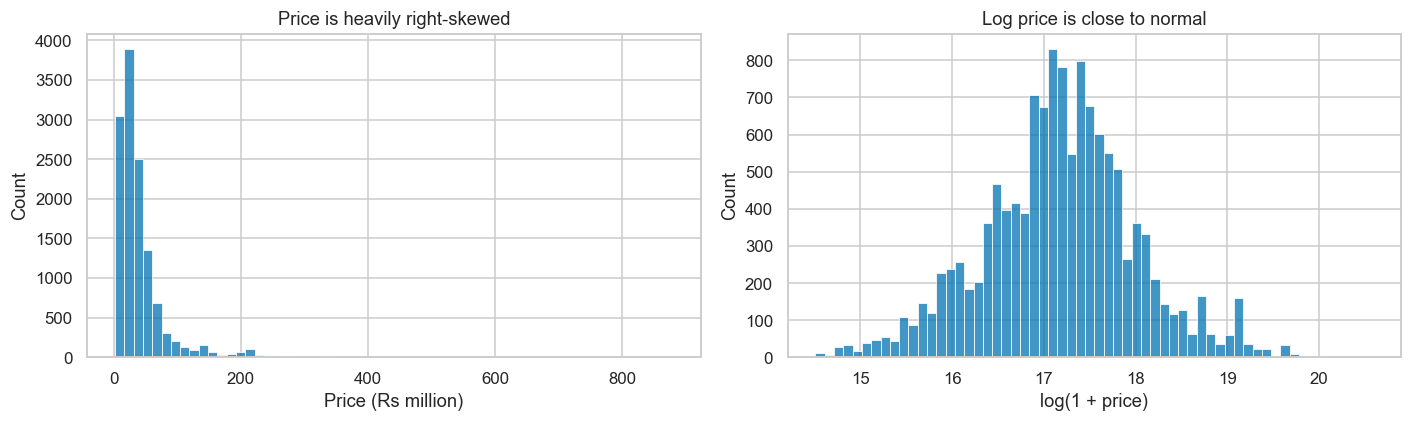

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data["price"] / 1e6, bins=60, ax=ax[0])

ax[0].set(title="Price is heavily right-skewed", xlabel="Price (Rs million)")
sns.histplot(np.log1p(data["price"]), bins=60, ax=ax[1])

ax[1].set(title="Log price is close to normal", xlabel="log(1 + price)")
plt.tight_layout(); plt.show()

A few luxury homes stretch the price scale. Modelling log(price) stops these from dominating the loss, so the target is log transformed.

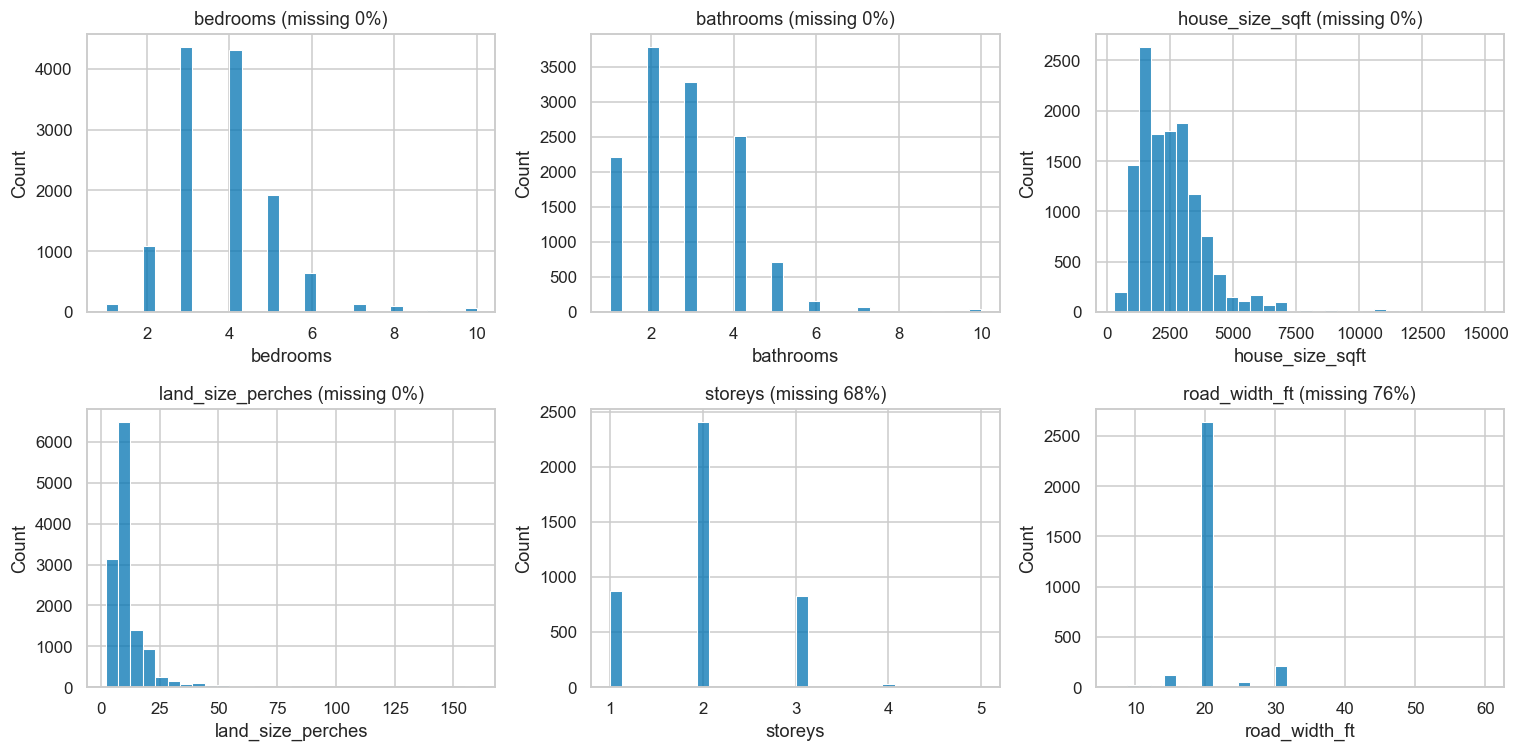

In [8]:
num_cols = ["bedrooms", "bathrooms", "house_size_sqft", "land_size_perches", "storeys", "road_width_ft"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))

# Plot histograms for each numerical column
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(data[col].dropna(), bins=30, ax=ax)
    ax.set_title(f"{col} (missing {data[col].isna().mean():.0%})")
plt.tight_layout(); plt.show()

Structured fields are complete. Storeys and road width come from free text, so many values are missing; tree models handle missing values well, and the gaps are imputed in preprocessing.

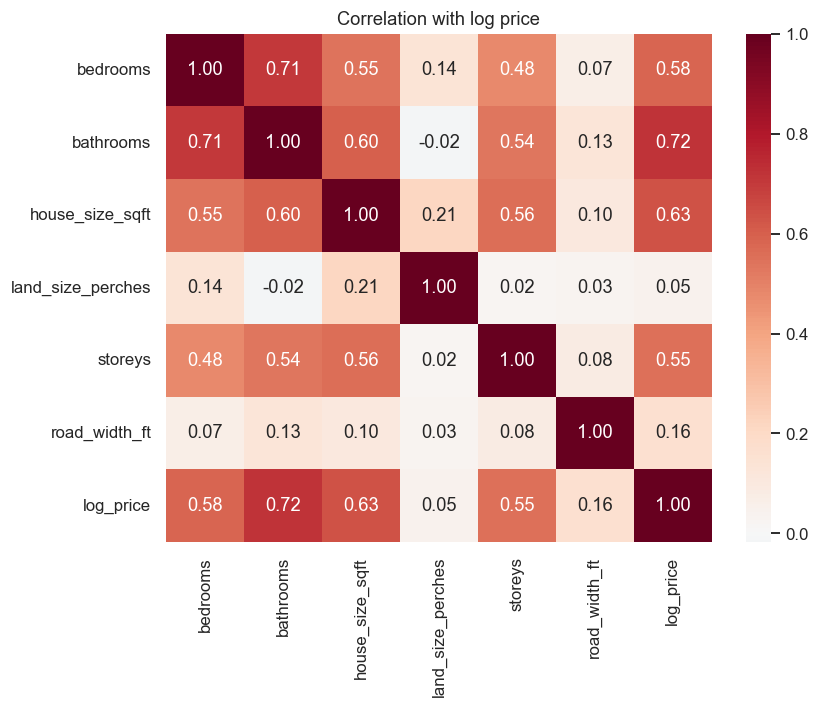

In [9]:
corr = data[num_cols + ["price"]].assign(log_price=np.log1p(data["price"])).drop(columns="price").corr()
plt.figure(figsize=(8, 6))

sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlation with log price"); plt.show()

Bathrooms, house size and bedrooms correlate most with price, and with each other. Land size shows almost no linear correlation, because small urban plots are often expensive, so its effect depends on location. Tree based models capture this kind of interaction and are not harmed by overlapping features.

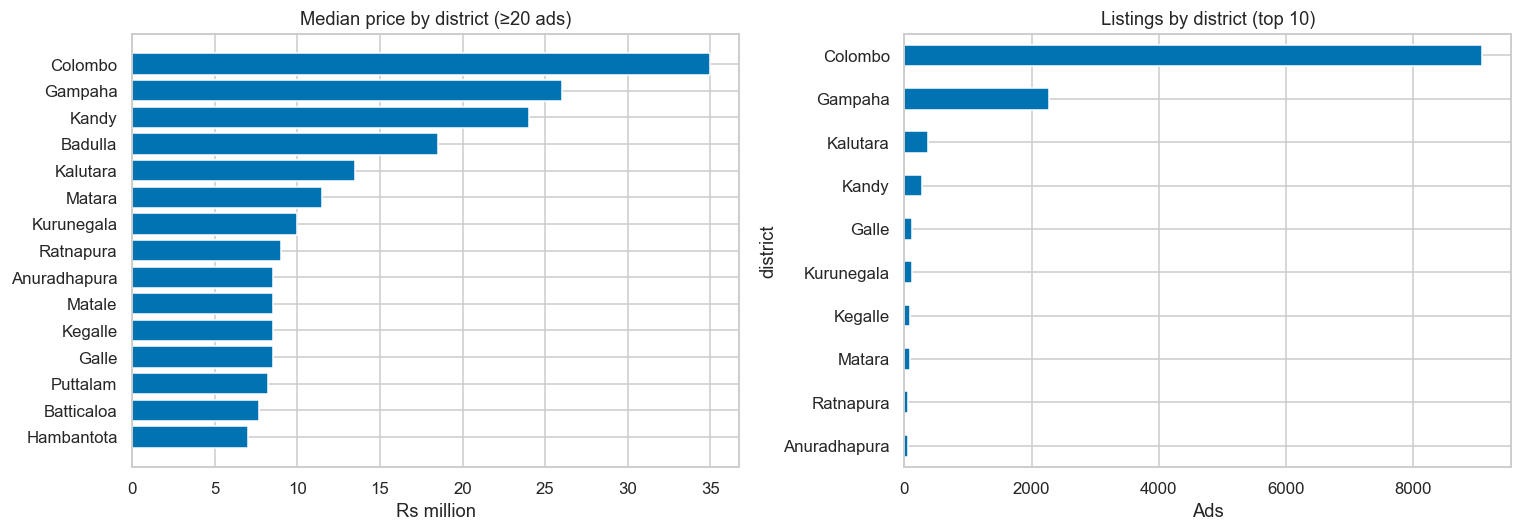

In [10]:
top = data.groupby("district")["price"].agg(["median", "count"]).query("count >= 20").sort_values("median")
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].barh(top.index, top["median"] / 1e6)
ax[0].set(title="Median price by district (≥20 ads)", xlabel="Rs million")
data["district"].value_counts().head(10).sort_values().plot.barh(ax=ax[1])
ax[1].set(title="Listings by district (top 10)", xlabel="Ads")
plt.tight_layout(); plt.show()

Location has a strong effect on price, and the data is concentrated in Colombo and Gampaha. Predictions for other districts will be less certain, which is noted as a limitation.

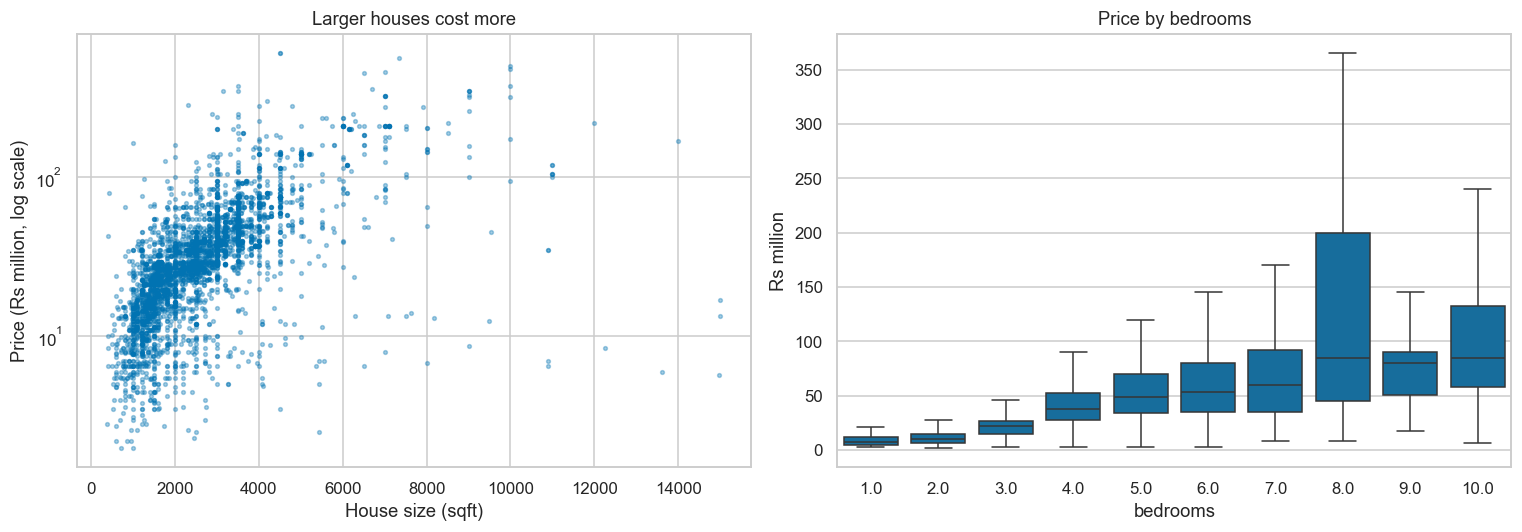

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sample = data.sample(min(4000, len(data)), random_state=RANDOM_STATE)
ax[0].scatter(sample["house_size_sqft"], sample["price"] / 1e6, s=6, alpha=0.35)
ax[0].set(yscale="log", title="Larger houses cost more", xlabel="House size (sqft)", ylabel="Price (Rs million, log scale)")
sns.boxplot(data=data, x="bedrooms", y=data["price"] / 1e6, ax=ax[1], showfliers=False)
ax[1].set(title="Price by bedrooms", ylabel="Rs million")
plt.tight_layout(); plt.show()

In [12]:
# Analyze the effect of each keyword on price
kw_effect = pd.DataFrame({
    kw: [data.loc[data[kw] == 1, "price"].median() / data.loc[data[kw] == 0, "price"].median(), data[kw].mean()]
    for kw in KEYWORDS
}, index=["median_price_ratio", "share_of_ads"]).T.sort_values("median_price_ratio")
kw_effect.round(2)

,median_price_ratio,share_of_ads
kw_clear_deed,0.93,0.03
kw_parking,1.00,0.07
kw_main_road,1.12,0.04
kw_brand_new,1.26,0.32
kw_luxury,1.70,0.32
kw_solar,1.75,0.01
kw_ac,1.82,0.07
kw_pool,2.79,0.02


A ratio above 1 means ads mentioning the keyword have higher median prices. These raw ratios mix effects (luxury homes are also bigger), so SHAP is used later to separate each feature's contribution.

In [13]:
ads_per_user = data["user"].value_counts()
print("Sellers:", ads_per_user.size, "| Top 5 sellers' ad counts:", ads_per_user.head().tolist())
print(f"Top 10 sellers post {ads_per_user.head(10).sum() / len(data):.0%} of all ads")

Sellers: 1981 | Top 5 sellers' ad counts: [712, 540, 421, 371, 361]
Top 10 sellers post 31% of all ads


**Key EDA findings & decisions**
1. Price is right skewed: model log(price).
2. Size and room counts drive price but overlap, and land size depends on location: use tree based models, which handle correlated features and interactions.
3. Location matters strongly but predictions outside the Western Province rest on little data: a model that reports its own uncertainty (NGBoost) is useful here.
4. Text derived features are often missing: impute them in preprocessing.
5. A few agents post many near identical ads: split train/test by seller so the test score is honest.

## 6. Train/test split
A group split by seller keeps all of a seller's ads on one side, preventing near duplicate ads from leaking into the test set.

In [14]:
FEATURES_NUM = ["bedrooms", "bathrooms", "house_size_sqft", "land_size_perches", "storeys", "road_width_ft"] + list(KEYWORDS)
FEATURES_CAT = ["district", "city"]
FEATURES = FEATURES_NUM + FEATURES_CAT

# Prepare the feature matrix and target variable
X = data[FEATURES].copy()
y = np.log1p(data["price"])
groups = data["user"]

# Split the data into train and test sets
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train = groups.iloc[train_idx]

cv_splits = list(GroupKFold(n_splits=CV_FOLDS).split(X_train, y_train, g_train))
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (10092, 16) | Test: (2715, 16)


## 7. Preprocessing
- **Numeric:** median imputation. No scaling, because tree based models split on thresholds and are unaffected by feature scale.
- **Categorical:** ordinal encoding. Trees can split on the codes, and this keeps the feature count small.

In [15]:
preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), FEATURES_NUM),
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), FEATURES_CAT),
], verbose_feature_names_out=False).set_output(transform="pandas")

def tree_pipeline(model):
    return Pipeline([("prep", preprocess), ("model", model)])

def ngb_model(n_estimators=500, learning_rate=0.01, max_depth=3, min_samples_leaf=1, minibatch_frac=1.0, col_sample=1.0):
    base = DecisionTreeRegressor(max_depth=max_depth, min_samples_leaf=min_samples_leaf, random_state=RANDOM_STATE)
    return tree_pipeline(NGBRegressor(Dist=Normal, Base=base, n_estimators=n_estimators, learning_rate=learning_rate,
                                      minibatch_frac=minibatch_frac, col_sample=col_sample,
                                      random_state=RANDOM_STATE, verbose=False))

# Predicted distribution (mean and standard deviation of log price) for each row
def ngb_dist(model, X):
    params = model.named_steps["model"].pred_dist(model.named_steps["prep"].transform(X)).params
    return params["loc"], params["scale"]

## 8. The algorithm: NGBoost
**Why NGBoost.** Most models return one price. NGBoost returns a probability distribution for every house, here a normal distribution on log price, which equals a log normal distribution on price. So each estimate comes with its own uncertainty: narrow for typical Colombo houses, wide for rare houses where the data is thin.

**How it works.** NGBoost is gradient boosting for distribution parameters. Each boosting step fits small trees that update both the mean and the spread of the distribution. It uses the *natural gradient*, which takes the shape of the distribution into account, so the mean and the spread are learned in a stable, balanced way. Training minimises the negative log likelihood, so the model is rewarded for being accurate *and* honest about its uncertainty.

**How it differs from standard models.** Decision trees, Random Forest, XGBoost, linear models and kNN all predict a single value. NGBoost learns a second output, the uncertainty, and that uncertainty depends on the features of each house.

## 9. Models with default parameters
Random Forest and XGBoost are the baselines. Their scores are the reference point for tuning and for NGBoost.

In [16]:
# Evaluate the point predictions of a model
def evaluate(model, name):
    pred_log = model.predict(X_test)
    actual, pred = np.expm1(y_test), np.expm1(pred_log)
    return {
        "model": name,
        "RMSE (log)": np.sqrt(mean_squared_error(y_test, pred_log)),
        "R2 (log)": r2_score(y_test, pred_log),
        "MAE (Rs M)": mean_absolute_error(actual, pred) / 1e6,
        "MAPE (%)": mean_absolute_percentage_error(actual, pred) * 100,
    }

default_models = {
    "Random Forest": tree_pipeline(RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
    "XGBoost": tree_pipeline(XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1)),
    "NGBoost": ngb_model(),
}
default_results = []
for name, model in default_models.items():
    model.fit(X_train, y_train)
    default_results.append(evaluate(model, name))
pd.DataFrame(default_results).set_index("model").round(3)

,RMSE (log),R2 (log),MAE (Rs M),MAPE (%)
model,,,,
Random Forest,0.410,0.747,10.966,27.623
XGBoost,0.390,0.772,10.730,27.054
NGBoost,0.419,0.736,12.851,30.418


## 10. Hyperparameter tuning
Optuna searches each model's main parameters, scoring every candidate with group aware cross validation on the training set only. Each search starts from a sensible setting, so tuning can only improve on it. NGBoost gets fewer trials because it is slower to train.

In [17]:
def cv_rmse(model):
    scores = cross_val_score(model, X_train, y_train, cv=cv_splits, scoring="neg_root_mean_squared_error")
    return -scores.mean()

# Search spaces
def rf_space(t):
    return tree_pipeline(RandomForestRegressor(
        n_estimators=t.suggest_int("n_estimators", 200, 600, step=100),
        max_depth=t.suggest_int("max_depth", 8, 30),
        min_samples_leaf=t.suggest_int("min_samples_leaf", 1, 10),
        max_features=t.suggest_float("max_features", 0.3, 1.0),
        random_state=RANDOM_STATE, n_jobs=-1))

def xgb_space(t):
    return tree_pipeline(XGBRegressor(
        n_estimators=t.suggest_int("n_estimators", 300, 1500, step=100),
        learning_rate=t.suggest_float("learning_rate", 0.01, 0.2, log=True),
        max_depth=t.suggest_int("max_depth", 3, 10),
        min_child_weight=t.suggest_float("min_child_weight", 1, 20, log=True),
        subsample=t.suggest_float("subsample", 0.6, 1.0),
        colsample_bytree=t.suggest_float("colsample_bytree", 0.5, 1.0),
        reg_lambda=t.suggest_float("reg_lambda", 1e-3, 10, log=True),
        random_state=RANDOM_STATE, n_jobs=-1))

def ngb_space(t):
    return ngb_model(
        n_estimators=t.suggest_int("n_estimators", 300, 1000, step=100),
        learning_rate=t.suggest_float("learning_rate", 0.01, 0.1, log=True),
        max_depth=t.suggest_int("max_depth", 3, 7),
        min_samples_leaf=t.suggest_int("min_samples_leaf", 1, 20),
        minibatch_frac=t.suggest_float("minibatch_frac", 0.5, 1.0),
        col_sample=t.suggest_float("col_sample", 0.5, 1.0))

START_POINTS = {
    "Random Forest": {"n_estimators": 300, "max_depth": 30, "min_samples_leaf": 1, "max_features": 1.0},
    "XGBoost": {"n_estimators": 300, "learning_rate": 0.1, "max_depth": 6, "min_child_weight": 1, "subsample": 1.0, "colsample_bytree": 1.0, "reg_lambda": 1.0},
    "NGBoost": {"n_estimators": 500, "learning_rate": 0.05, "max_depth": 5, "min_samples_leaf": 5, "minibatch_frac": 0.8, "col_sample": 0.8},
}
TRIALS = {"NGBoost": NGB_TRIALS}
spaces = {"Random Forest": rf_space, "XGBoost": xgb_space, "NGBoost": ngb_space}
tuned, cv_scores, best_params = {}, {}, {}

# Tune each model with Optuna
for name, space in spaces.items():
    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    study.enqueue_trial(START_POINTS[name])
    study.optimize(lambda t: cv_rmse(space(t)), n_trials=TRIALS.get(name, N_TRIALS))
    best_params[name] = study.best_params
    cv_scores[name] = study.best_value
    tuned[name] = space(optuna.trial.FixedTrial(study.best_params)).fit(X_train, y_train)
    print(f"{name:14s} CV RMSE (log): {study.best_value:.4f}  {study.best_params}")

Random Forest  CV RMSE (log): 0.4013  {'n_estimators': 300, 'max_depth': 30, 'min_samples_leaf': 2, 'max_features': 0.39871925471080316}
XGBoost        CV RMSE (log): 0.3810  {'n_estimators': 700, 'learning_rate': 0.015550574289908333, 'max_depth': 9, 'min_child_weight': 3.569114088570525, 'subsample': 0.744364975646713, 'colsample_bytree': 0.6173497804033278, 'reg_lambda': 0.007788778325605524}
NGBoost        CV RMSE (log): 0.3842  {'n_estimators': 400, 'learning_rate': 0.013320532798292067, 'max_depth': 7, 'min_samples_leaf': 3, 'minibatch_frac': 0.580511965457201, 'col_sample': 0.5337143834654948}


## 11. Evaluation and comparison
All models are scored on the same held out test sellers. Errors in rupees (MAE, MAPE) are what a buyer would actually feel.

In [18]:
results = pd.DataFrame([evaluate(m, n) for n, m in tuned.items()]).set_index("model")
results["CV RMSE (log)"] = pd.Series(cv_scores)
comparison = results.join(pd.DataFrame(default_results).set_index("model")[["RMSE (log)"]].rename(columns={"RMSE (log)": "Default RMSE (log)"}))
comparison = comparison.sort_values("RMSE (log)")
comparison.round(3)

,RMSE (log),R2 (log),MAE (Rs M),MAPE (%),CV RMSE (log),Default RMSE (log)
model,,,,,,
XGBoost,0.370,0.794,10.129,25.320,0.381,0.390
NGBoost,0.379,0.784,10.855,26.344,0.384,0.419
Random Forest,0.408,0.750,11.434,27.504,0.401,0.410


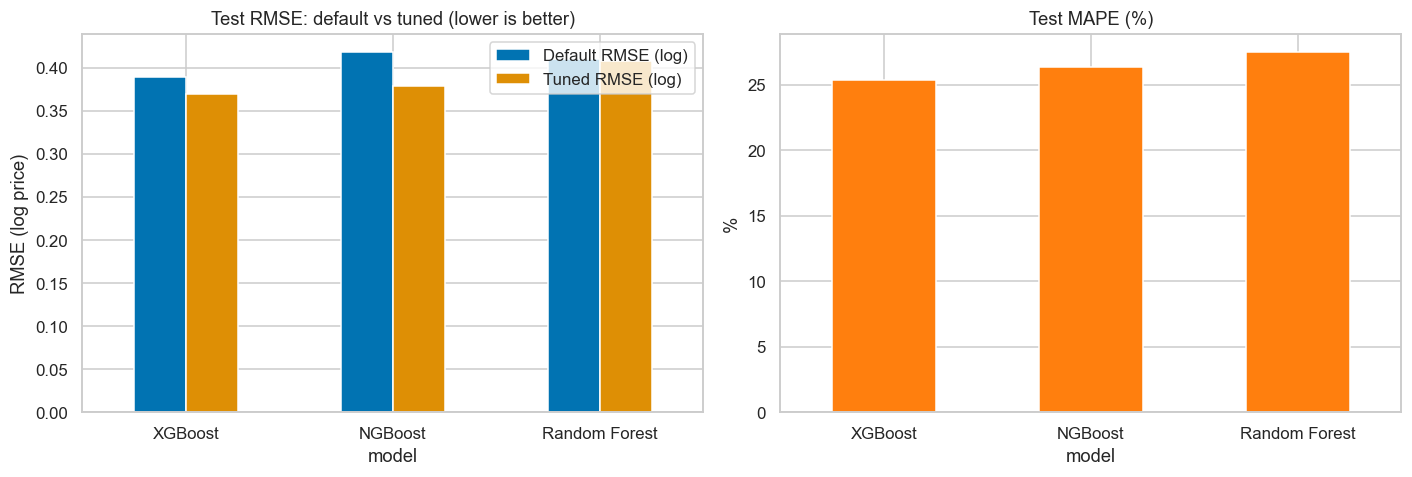

In [19]:
# Plot comparison of default and tuned models
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
comparison[["Default RMSE (log)", "RMSE (log)"]].rename(columns={"RMSE (log)": "Tuned RMSE (log)"}).plot.bar(ax=ax[0], rot=0)
ax[0].set(title="Test RMSE: default vs tuned (lower is better)", ylabel="RMSE (log price)")
comparison["MAPE (%)"].plot.bar(ax=ax[1], rot=0, color="tab:orange")
ax[1].set(title="Test MAPE (%)", ylabel="%")
plt.tight_layout(); plt.show()

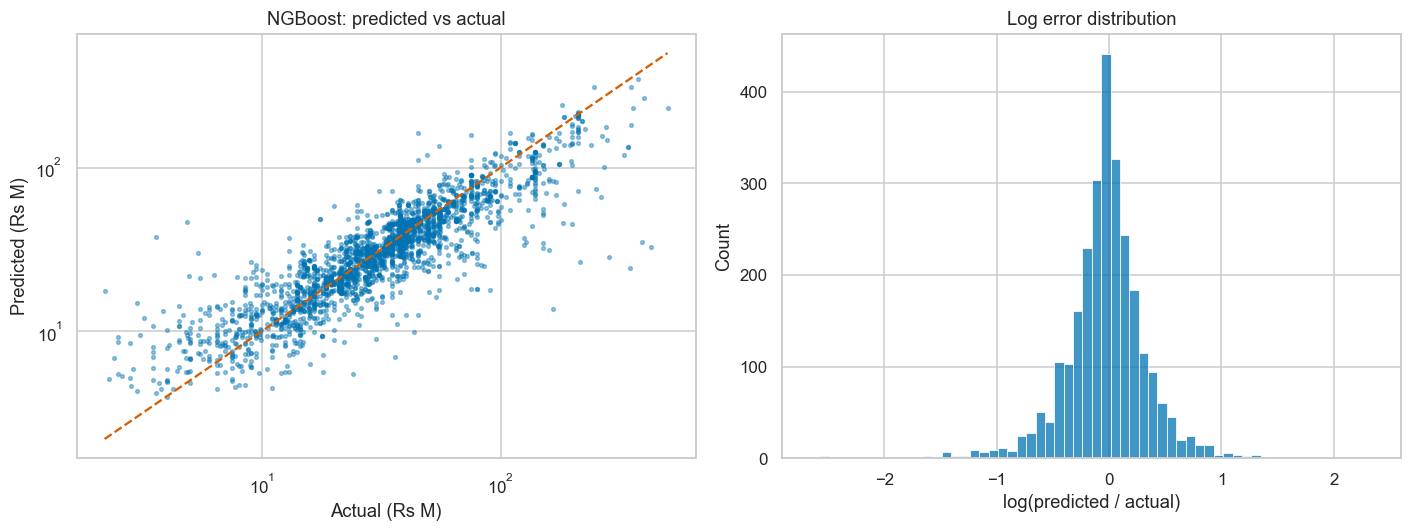

In [20]:
# NGBoost is the final model: it is the new algorithm and the only one that gives a per house uncertainty
best_name = "NGBoost"
final_model = tuned[best_name]

pred = np.expm1(final_model.predict(X_test)); actual = np.expm1(y_test)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(actual / 1e6, pred / 1e6, s=6, alpha=0.4)
lims = [actual.min() / 1e6, actual.max() / 1e6]
ax[0].plot(lims, lims, "r--"); ax[0].set(xscale="log", yscale="log", title="NGBoost: predicted vs actual", xlabel="Actual (Rs M)", ylabel="Predicted (Rs M)")
sns.histplot(np.log(pred / actual), bins=60, ax=ax[1]); ax[1].set(title="Log error distribution", xlabel="log(predicted / actual)")
plt.tight_layout(); plt.show()

**Why NGBoost is the final model**
- Its point accuracy is compared directly with the taught baselines above. If it is close to XGBoost, the extra uncertainty output makes it the more useful model.
- It is the only model that tells the user *how sure* it is about each house, which matters because the data is uneven across districts.
- Errors are roughly centred around zero, so the model does not systematically over or under price houses.

## 12. Uncertainty: are the price ranges reliable?
An 80% range should contain the actual price for about 80% of houses. Ranges learned on training data are often too narrow on new sellers, so they are **calibrated**: one scale factor is learned on the cross validation folds (never the test set) and applied to every range.

In [21]:
# Learn one calibration factor from out of fold predictions
z_scores = []
for tr, va in cv_splits:
    m = clone(final_model).fit(X_train.iloc[tr], y_train.iloc[tr])
    loc, scale = ngb_dist(m, X_train.iloc[va])
    z_scores.append(np.abs(y_train.iloc[va].values - loc) / scale)
INTERVAL_SCALE = float(np.quantile(np.concatenate(z_scores), 0.8) / norm.ppf(0.9))
print(f"Calibration factor: {INTERVAL_SCALE:.2f} (1.00 means the raw ranges were already right)")

# Coverage and width of the ranges on the test set
loc, scale = ngb_dist(final_model, X_test)
def interval_stats(level, factor):
    z = norm.ppf(0.5 + level / 2) * scale * factor
    inside = (y_test.values >= loc - z) & (y_test.values <= loc + z)
    width = (np.expm1(loc + z) - np.expm1(loc - z)) / np.expm1(loc)
    return inside.mean() * 100, np.median(width) * 100

rows = []
for level in [0.8, 0.95]:
    for label, factor in [("raw", 1.0), ("calibrated", INTERVAL_SCALE)]:
        cov, width = interval_stats(level, factor)
        rows.append({"range": f"{level:.0%}", "version": label, "coverage (%)": cov, "median width (% of price)": width})
nll = -norm.logpdf(y_test.values, loc, scale * INTERVAL_SCALE).mean()
print(f"Test negative log likelihood (lower is better): {nll:.3f}")
pd.DataFrame(rows).round(1)

Calibration factor: 1.38 (1.00 means the raw ranges were already right)
Test negative log likelihood (lower is better): 0.255


,range,version,coverage (%),median width (% of price)
0,80%,raw,71.1,60.3
1,80%,calibrated,84.9,84.0
2,95%,raw,88.4,94.0
3,95%,calibrated,95.7,133.2


In [22]:
# Uncertainty by region: does the model know when it knows less?
WESTERN = {"Colombo", "Gampaha", "Kalutara"}
region = np.where(X_test["district"].isin(WESTERN), "Western Province", "Other provinces")
z80 = norm.ppf(0.9) * scale * INTERVAL_SCALE
inside = (y_test.values >= loc - z80) & (y_test.values <= loc + z80)
by_region = pd.DataFrame({"region": region, "std (log)": scale * INTERVAL_SCALE, "inside 80% range": inside,
                          "abs error (log)": np.abs(y_test.values - loc)})
by_region.groupby("region").agg(houses=("region", "size"), avg_uncertainty=("std (log)", "mean"),
                                avg_abs_error=("abs error (log)", "mean"), coverage_80=("inside 80% range", "mean")).round(3)

,houses,avg_uncertainty,avg_abs_error,coverage_80
region,,,,
Other provinces,188,0.535,0.435,0.766
Western Province,2527,0.325,0.241,0.855


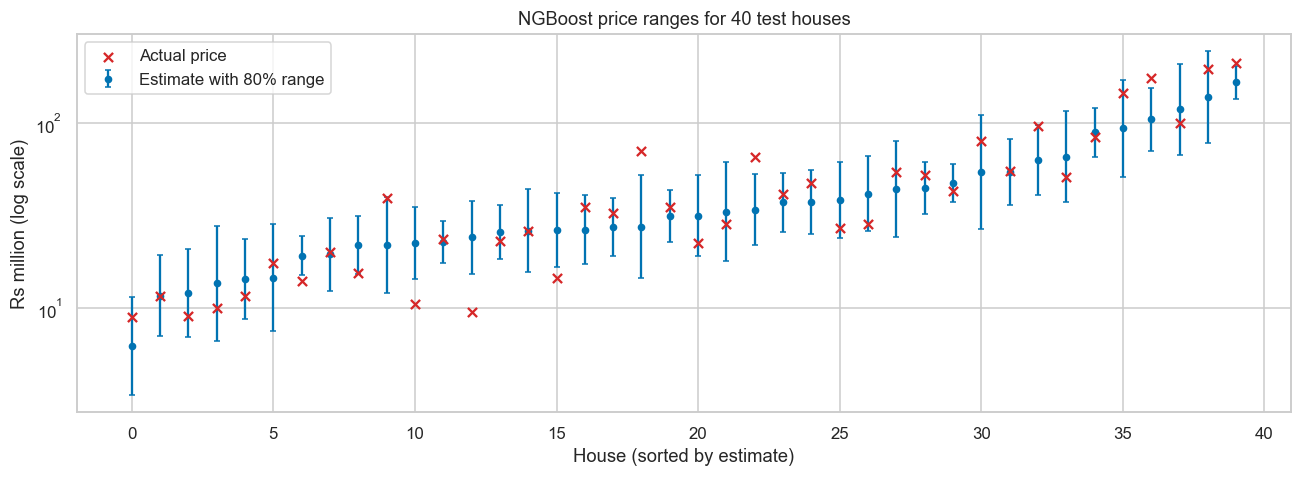

In [23]:
# Ranges for 40 random test houses
idx = np.random.RandomState(RANDOM_STATE).choice(len(X_test), 40, replace=False)
order = idx[np.argsort(loc[idx])]
mid, lo, hi = np.expm1(loc[order]) / 1e6, np.expm1(loc[order] - z80[order]) / 1e6, np.expm1(loc[order] + z80[order]) / 1e6
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.errorbar(range(40), mid, yerr=[mid - lo, hi - mid], fmt="o", ms=4, capsize=2, label="Estimate with 80% range")
ax.scatter(range(40), np.expm1(y_test.values[order]) / 1e6, color="tab:red", marker="x", zorder=3, label="Actual price")
ax.set(yscale="log", title="NGBoost price ranges for 40 test houses", xlabel="House (sorted by estimate)", ylabel="Rs million (log scale)")
ax.legend(); plt.tight_layout(); plt.show()

## 13. Explainability: SHAP for the price
SHAP measures how much each feature pushes the predicted (mean log) price above or below the average. NGBoost is a tree ensemble, so the fast TreeExplainer works on it directly (`model_output=0` is the mean).

In [24]:
ngb = final_model.named_steps["model"]
X_shap = X_test.sample(min(1000, len(X_test)), random_state=RANDOM_STATE)
X_view = final_model.named_steps["prep"].transform(X_shap)
shap_values = shap.TreeExplainer(ngb, model_output=0)(X_view)

shap_importance = pd.Series(np.abs(shap_values.values).mean(axis=0), index=X_view.columns).sort_values(ascending=False)
print(shap_importance.round(3).head(10))

bathrooms            0.249
house_size_sqft      0.190
city                 0.109
district             0.098
land_size_perches    0.076
bedrooms             0.074
kw_luxury            0.054
kw_ac                0.013
kw_brand_new         0.010
storeys              0.007
dtype: float64


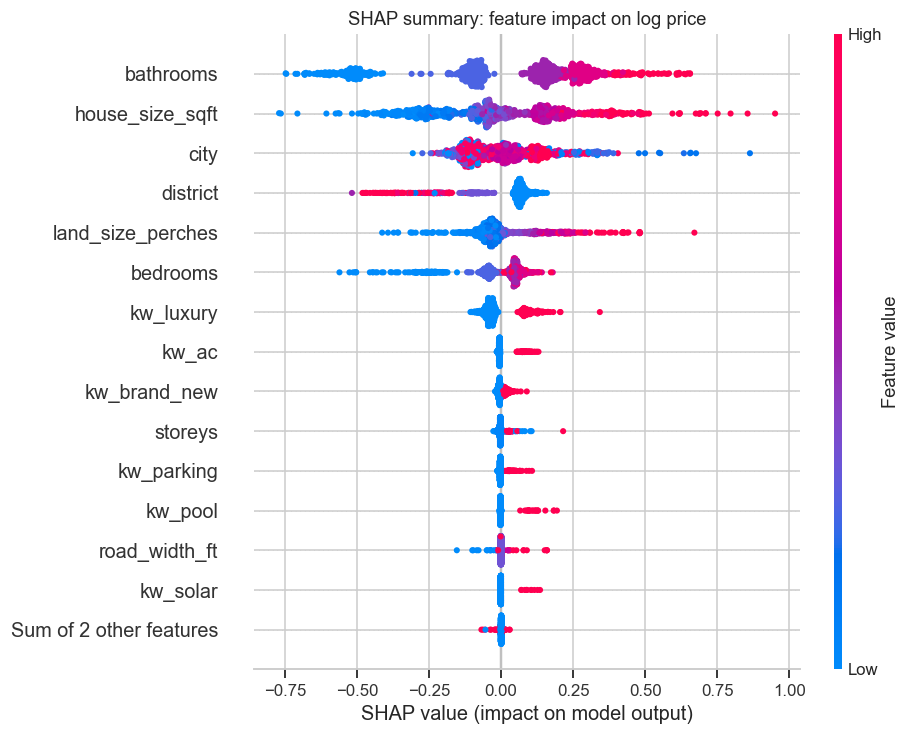

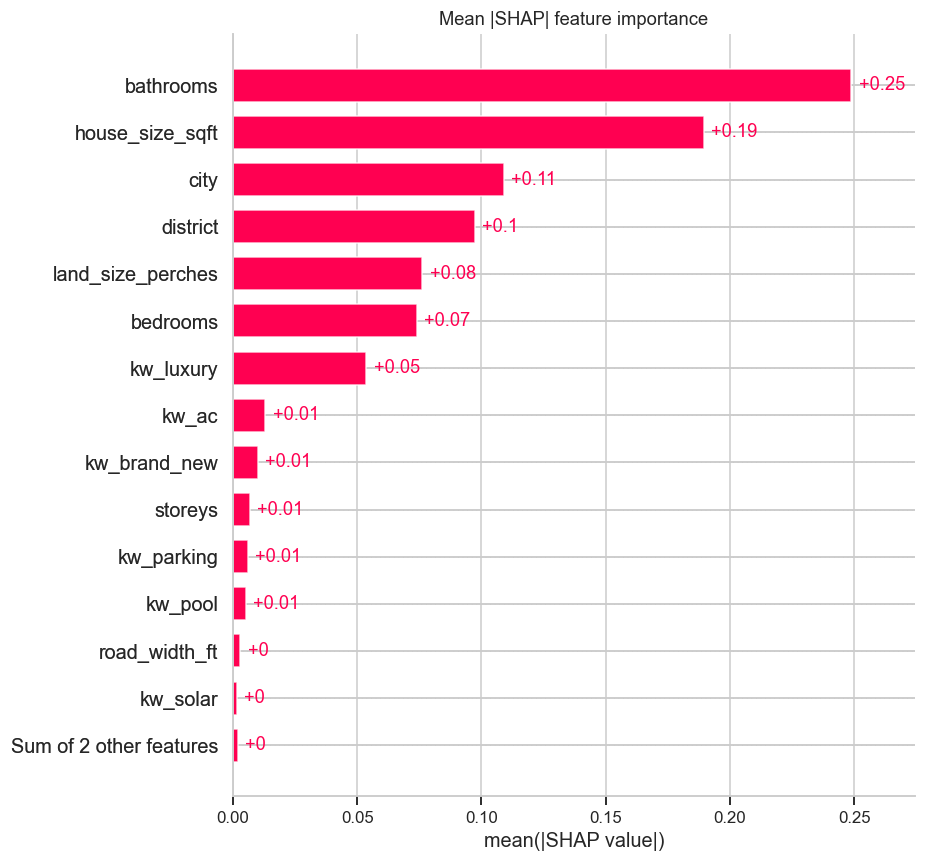

In [25]:
# Plot SHAP values
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title("SHAP summary: feature impact on log price"); plt.show()
shap.plots.bar(shap_values, max_display=15, show=False)
plt.title("Mean |SHAP| feature importance"); plt.show()

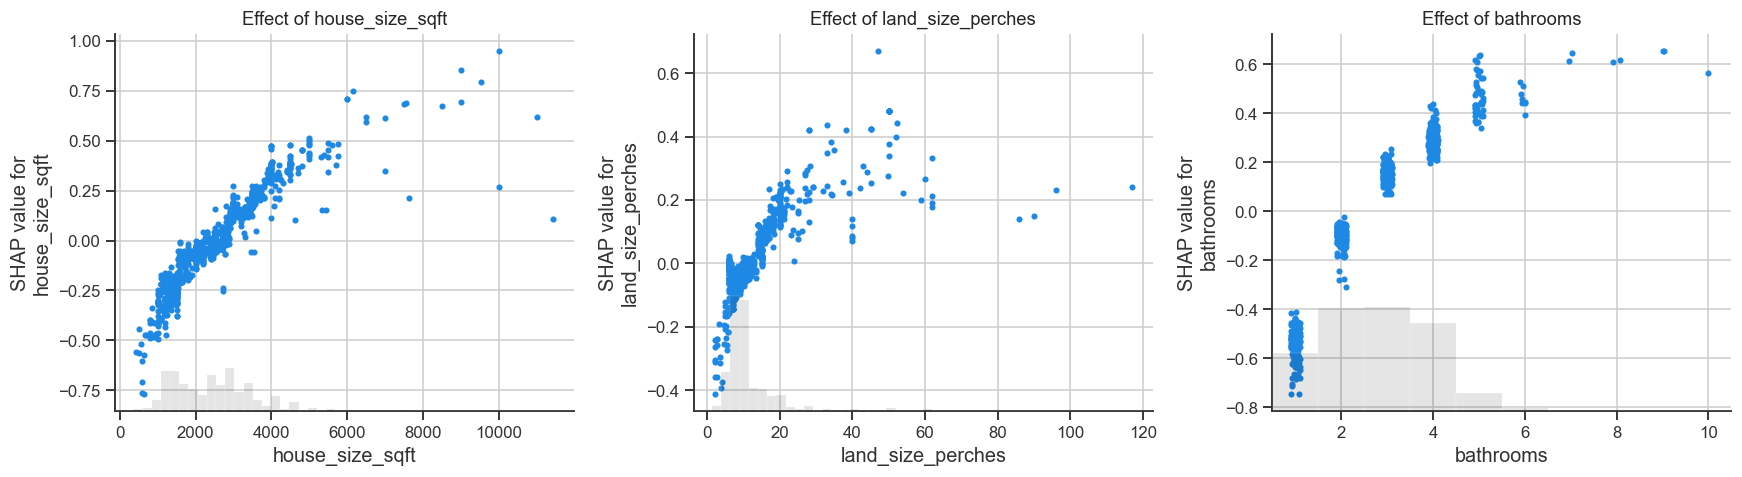

In [26]:
# Plot SHAP values
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, feat in zip(axes, ["house_size_sqft", "land_size_perches", "bathrooms"]):
    shap.plots.scatter(shap_values[:, feat], ax=ax, show=False)
    ax.set_title(f"Effect of {feat}")
plt.tight_layout(); plt.show()

Actual price: Rs 35,000,000


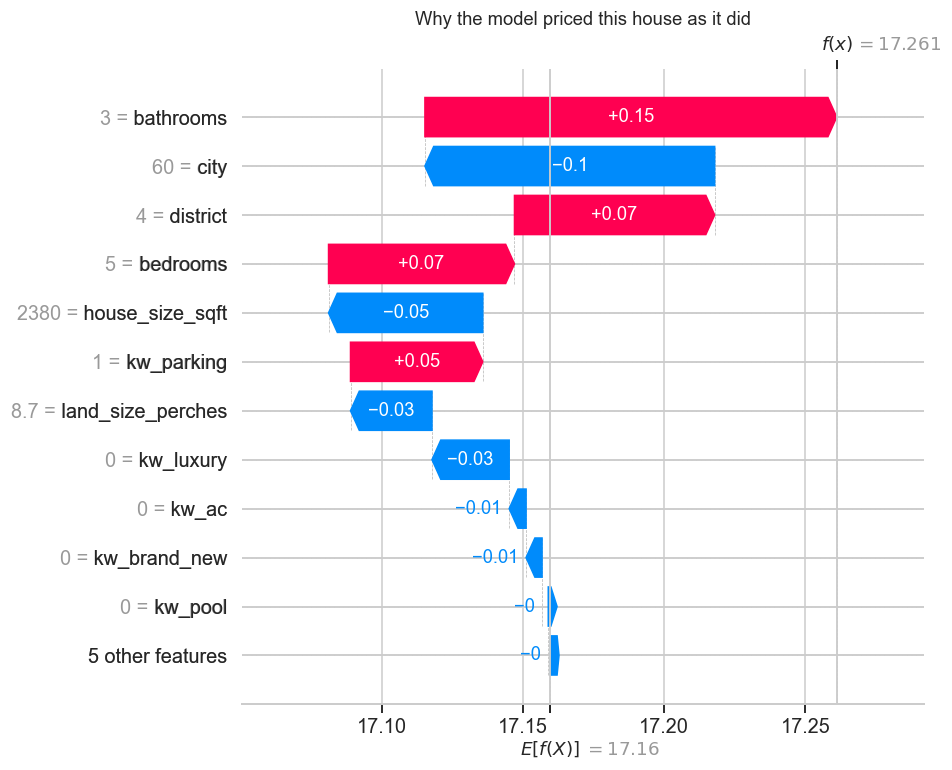

In [27]:
# Plot SHAP values for a specific instance
i = 0
print(f"Actual price: Rs {np.expm1(y_test.loc[X_shap.index[i]]):,.0f}")
shap.plots.waterfall(shap_values[i], max_display=12, show=False)
plt.title("Why the model priced this house as it did"); plt.show()

## 14. Explainability: SHAP for the uncertainty
Because NGBoost also learns the spread of each prediction, SHAP can explain **what makes the model unsure** (`model_output=1` is the log of the standard deviation). This is something single value models cannot show.

kw_luxury            0.112
kw_brand_new         0.107
city                 0.102
land_size_perches    0.080
house_size_sqft      0.053
bedrooms             0.043
bathrooms            0.036
kw_ac                0.024
district             0.019
storeys              0.008
dtype: float64


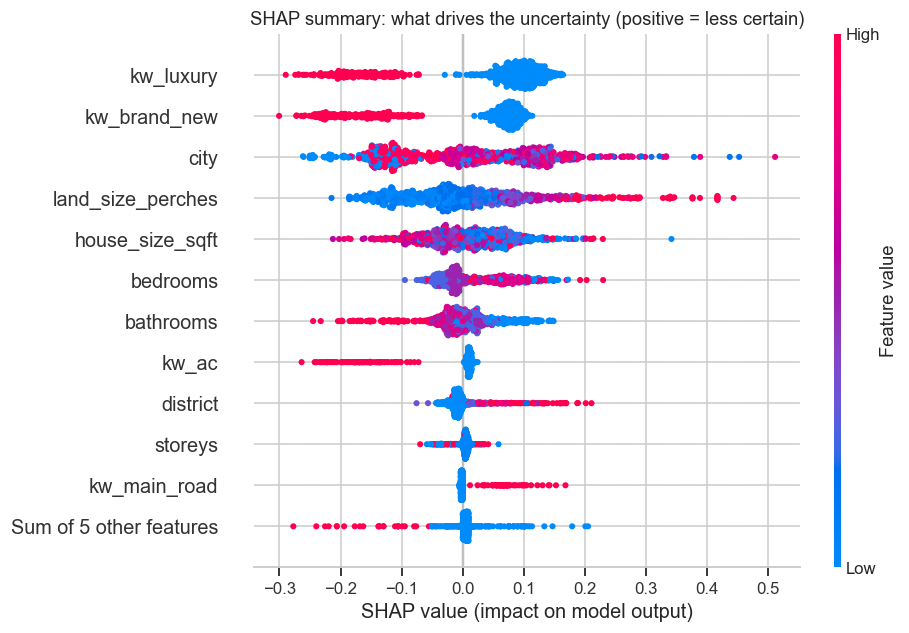

In [28]:
shap_scale = shap.TreeExplainer(ngb, model_output=1)(X_view)
scale_importance = pd.Series(np.abs(shap_scale.values).mean(axis=0), index=X_view.columns).sort_values(ascending=False)
print(scale_importance.round(3).head(10))
shap.plots.beeswarm(shap_scale, max_display=12, show=False)
plt.title("SHAP summary: what drives the uncertainty (positive = less certain)"); plt.show()

## 15. Explainability: LIME
LIME fits a simple local model around one house to show which features drove that specific prediction.

Categories are converted to numeric codes for LIME and decoded back before prediction.

House 0: actual Rs 35,000,000 | predicted Rs 31,362,709


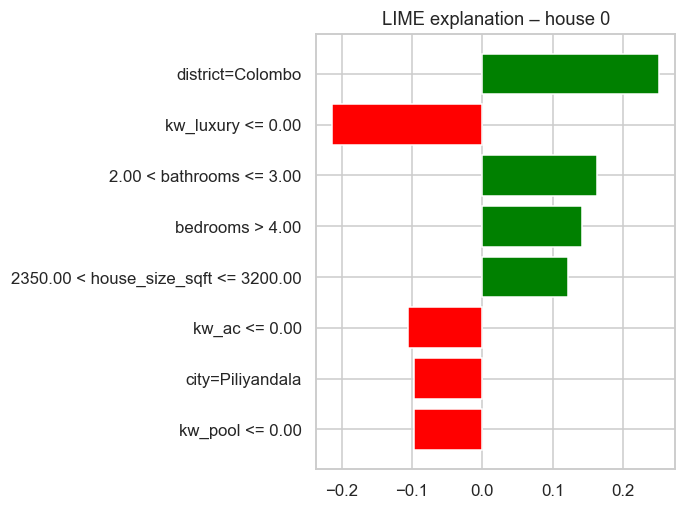

House 1: actual Rs 80,000,000 | predicted Rs 54,250,722


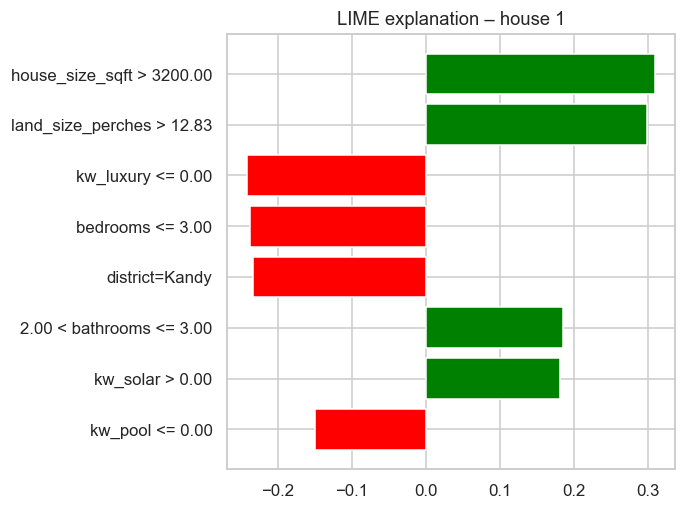

In [29]:
cat_encoder = OrdinalEncoder().fit(X_train[FEATURES_CAT])
cat_names = {FEATURES.index(c): list(cats) for c, cats in zip(FEATURES_CAT, cat_encoder.categories_)}

# Encode dataFrame for LIME
def encode_for_lime(frame):
    out = frame[FEATURES].copy()
    out[FEATURES_NUM] = out[FEATURES_NUM].fillna(X_train[FEATURES_NUM].median())
    out[FEATURES_CAT] = cat_encoder.transform(frame[FEATURES_CAT])
    return out.values.astype(float)

def lime_predict(arr):
    frame = pd.DataFrame(arr, columns=FEATURES)
    for c in FEATURES_CAT:
        idx = FEATURES.index(c)
        frame[c] = [cat_names[idx][int(round(v))] for v in frame[c]]
    return final_model.predict(frame[FEATURES])

# Initialize LIME explainer
lime_explainer = LimeTabularExplainer(
    encode_for_lime(X_train), feature_names=FEATURES, mode="regression",
    categorical_features=list(cat_names), categorical_names=cat_names,
    discretize_continuous=True, random_state=RANDOM_STATE)

for i in [0, 1]:
    row = X_shap.iloc[[i]]
    exp = lime_explainer.explain_instance(encode_for_lime(row)[0], lime_predict, num_features=8)
    print(f"House {i}: actual Rs {np.expm1(y_test.loc[row.index[0]]):,.0f} | predicted Rs {np.expm1(final_model.predict(row)[0]):,.0f}")
    exp.as_pyplot_figure(); plt.title(f"LIME explanation – house {i}"); plt.tight_layout(); plt.show()

**SHAP vs LIME**
- SHAP gives consistent global and local attributions, based on game theory.
- LIME gives a quick local approximation. Its explanations can vary between runs, because it relies on random sampling.
- For the same house, both methods should agree on the main drivers. Where they agree, the explanation is trustworthy.

## 16. Interpretation
Update these points to match the outputs of your run:
- **Price drivers:** read the top features from the SHAP summary (section 13) and the shape of their effects from the dependence plots.
- **Uncertainty drivers:** section 14 shows which features make the model less certain. Rare locations and unusual sizes usually widen the range.
- **Reliability:** after calibration, the 80% range should contain close to 80% of actual test prices (section 12).
- **Regional fairness:** compare the average uncertainty and error for the Western Province and other provinces. Wider ranges outside the Western Province mean the model is honest about knowing less there.
- **Limitations:** these are asking prices, not sale prices; the data is concentrated in the Western Province; road access and plot shape are only partly captured.

## 17. Save the model and test inference
The whole pipeline (preprocessing + NGBoost) is saved, so the app only needs raw inputs. The calibration factor is saved with it so the app can show calibrated ranges.

In [32]:
joblib.dump(final_model, "../models/house_price_model.pkl")

# Save model metadata
meta = {
    "model_name": best_name,
    "features_num": FEATURES_NUM,
    "features_cat": FEATURES_CAT,
    "keywords": list(KEYWORDS),
    "districts": sorted(data["district"].unique().tolist()),
    "cities_by_district": {d: sorted(g["city"].unique().tolist()) for d, g in data.groupby("district")},
    "test_mape": round(float(comparison.loc[best_name, "MAPE (%)"]), 1),
    "interval_scale": round(INTERVAL_SCALE, 4),
}
with open("../models/model_meta.json", "w") as f:
    json.dump(meta, f, indent=2)
print("Saved house_price_model.pkl and model_meta.json")

Saved house_price_model.pkl and model_meta.json


In [34]:
loaded = joblib.load("../models/house_price_model.pkl")

# Prediction function: estimate plus an 80% price range
def predict_price(house: dict, level: float = 0.8):
    row = pd.DataFrame([{f: house.get(f, np.nan) for f in FEATURES}])
    for kw in KEYWORDS:
        row[kw] = int(house.get(kw, 0))
    loc, scale = ngb_dist(loaded, row[FEATURES])
    z = norm.ppf(0.5 + level / 2) * scale[0] * meta["interval_scale"]
    return float(np.expm1(loc[0])), float(np.expm1(loc[0] - z)), float(np.expm1(loc[0] + z))

# Example usage
example = {"bedrooms": 4, "bathrooms": 3, "house_size_sqft": 2500, "land_size_perches": 10,
           "district": "Colombo", "city": "Maharagama", "storeys": 2, "kw_parking": 1}
est, lo, hi = predict_price(example)
print(f"Estimated price: Rs {est:,.0f}  (80% range: Rs {lo:,.0f} to Rs {hi:,.0f})")

Estimated price: Rs 35,254,413  (80% range: Rs 22,093,892 to Rs 56,254,173)
